In [1]:
# WA CI model training

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import pickle
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cf
from datetime import date, datetime, timedelta
import xarray as xr
import netCDF4 as nc
from utils.u_interpolate_small import regrid_irregular_quick
import utils.u_interpolate_small as uint
import utils.u_interpolate_xesmf as inter_x
from pathlib import Path
import glob
import calendar
import os
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix
import math
import time
from utils.netncc_functions import fill_nan_nearest, FSS_loss_gpu, create_mean_filter, get_previous_date
from utils.plot_functions import plot_maps_colorbar, plot_maps_colorbar_lsta
#from utils.netncc_classes_smap import ConvLayer, netncc, XarrayUNetDataset, evalUNetDataset
import warnings
import cartopy.crs as ccrs
import cartopy.feature as cf
import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.ticker as mticker
from mpl_toolkits.axes_grid1 import make_axes_locatable
import rasterio
import rioxarray
from portal_run.portal_netpci import netpci
from portal_run.portal_EA_realtime_dataset import RealtimeDatasetSmLSTA, RealtimeDatasetSm
from portal_run.portal_EA_realtime_dataset import RealtimeDatasetNoLand
from portal_run.read_CI_file import read_CI


GPU: NVIDIA A40 is available.


In [2]:
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} is available.")
else:
    print("No GPU available. Training will run on CPU.")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


GPU: NVIDIA A40 is available.


In [3]:
### user input
current_date = '20261007'
runtype= 'sm_lsta' #'sm_lsta'  'sm', 'nl'


In [4]:
# Define domain 
image_height= 1024 #lat
image_width= image_height #lon
out_channels = 1

if runtype== 'sm_lsta': 
    in_channels =10
elif runtype== 'sm':
    in_channels =8
elif runtype== 'nl':
    in_channels =6

# grid
resolution = 0.05
end_lat = 15.50  #25
start_lon = 3.0 #
reg_lat = np.arange(end_lat-resolution*image_height, end_lat, resolution)
reg_lon = np.arange(start_lon, start_lon+resolution*(image_height), resolution) 

# lightening weights
with open('portal_run/lightning_weights_0p05','rb') as file:
     inds_lt, weights_lt, shape_lt= pickle.load(file)
lighting_dir = '/prj/swift/MTG_flash_count/'
nx = 1400
ny = 1440

In [5]:
# define model and training setup
model = netpci(in_channels)# Training parameters
model = nn.DataParallel(model)
model = model.to(device)
#criterion = FSS_loss_gpu    #nn.BCEWithLogitsLoss()
#optimizer = optim.Adam(model.parameters(), lr=1e-4)

if runtype== 'sm_lsta': 
    #'sm', 'nl'
    model.load_state_dict(torch.load(
    'trained_models/EA_all_year_0p05deg_1024_LST_18km_LT_CI_resconv_unet.pth'))
    print('model read')
elif runtype== 'sm':
    model.load_state_dict(torch.load(
    'trained_models/EA_all_year_0p05deg_1024_18km_LT_CI_resconv_unet.pth'))
    print('model read')
elif runtype== 'nl':
    model.load_state_dict(torch.load(
    'trained_models/EA_all_year_0p05deg_1024_noLandInfo_18km_LT_CI_resconv_unet.pth'))
    print('model read')



model read


In [6]:
# use soil moisture as primary filename
sm_dir = '/mnt/HYDROLOGY/geotiff/ssa_soil_moisture_anomaly/'
filename_sm =  f'{sm_dir}{current_date}/ASCAT_dsm_{current_date}_am_6k_3857.tif'
ifs_dir =  '/prj/swift/ecmwf_windfc/'
filename_wind_100_cape= (ifs_dir+'/'+current_date[0:4]+'/'+current_date[4:6]+'/'+
                         'uv10tcwv_'+current_date+'0000.nc')
filename_wind_700=(ifs_dir+'/'+current_date[0:4]+'/'+current_date[4:6]+'/'+
                         'uv700_'+current_date+'0000.nc')

LST_dir = '/prj/swift/SEVIRI_LST/lsta_ssa/nrt/'
filename_lst=(
    LST_dir+current_date[0:6]+'/'+
    'LSASAF_lst_anom_Daymean_withmask_withHistClim_'+current_date+'_1700.nc')
 

filenames = [
    filename_sm,
    filename_wind_100_cape,
    filename_wind_700,
    filename_lst
]

missing_files = [f for f in filenames if not Path(f).exists()]

if missing_files:
    print("Missing files:")
    for f in missing_files:
        print(f)
else:
    print("All files exist.")

filenames

All files exist.


['/mnt/HYDROLOGY/geotiff/ssa_soil_moisture_anomaly/20261007/ASCAT_dsm_20261007_am_6k_3857.tif',
 '/prj/swift/ecmwf_windfc//2026/10/uv10tcwv_202610070000.nc',
 '/prj/swift/ecmwf_windfc//2026/10/uv700_202610070000.nc',
 '/prj/swift/SEVIRI_LST/lsta_ssa/nrt/202610/LSASAF_lst_anom_Daymean_withmask_withHistClim_20261007_1700.nc']

In [7]:
if runtype== 'sm_lsta': 
    inputs = RealtimeDatasetSmLSTA(current_date, filenames, in_channels)
elif runtype== 'sm':
    inputs = RealtimeDatasetSm(current_date, filenames, in_channels)
elif runtype== 'nl':
    inputs = RealtimeDatasetNoLand(current_date, filenames, in_channels)


inputs.shape

torch.Size([10, 1024, 1024])

/home/jawahm/miniforge3/envs/dl_gpu/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


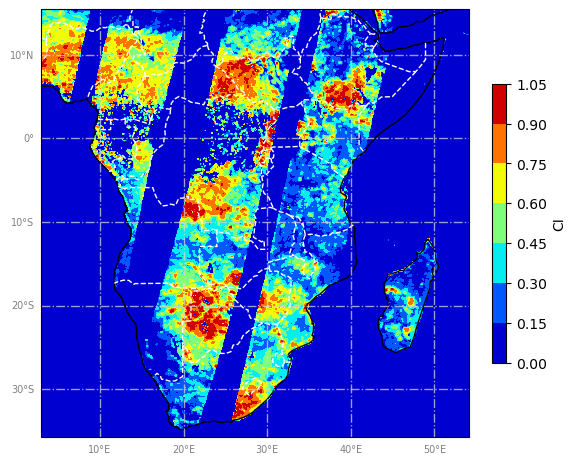

In [8]:
#train_input = dataset[day]
#train_ci = tmp[1]
fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(6,6),subplot_kw={'projection': ccrs.PlateCarree()})

plot_maps_colorbar(ax, reg_lon, reg_lat, inputs[0,:,:],
          levels_custom= None,cmap='jet',plot_label='CI',title=None)
#ax.set_xlim(xmin,xmax)
#ax.set_ylim(ymin,ymax)

#ax.set_ylim(start_lat,end_lat)
plt.show()

In [9]:
def plot_maps(ax, lon, lat, data,levels_custom,plot_map,plot_label):
    m=ax.contourf(lon, lat, data, transform=ccrs.PlateCarree(), levels=levels_custom,cmap=plot_map)  # this is the actual plot
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=1, color='gray', alpha=0.75, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
   # gl.xlocator = mticker.FixedLocator([25, 30, 35, 40, 45])
    #gl.ylocator = mticker.FixedLocator([-8, -4, 0, 4, 8])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 7, 'color': 'gray'}
    gl.ylabel_style = {'size': 7, 'color': 'gray'}
    ax.set_xlim(lon.min(),lon.max())
    ax.set_ylim(lat.min(),lat.max())

    # ax.set_title(title)
    # Countries
    ax.coastlines()   ## adds coastlines
    ax.add_feature(cf.BORDERS, linestyle='--')#,color='black') # adds country borders
    ax.add_feature(cf.OCEAN)
   # ax.add_feature(cf.LAKES,alpha=0.5)
    #cbar = plt.colorbar(m)  # adds colorbar
    cbar = plt.colorbar(m, fraction=0.03, pad=0.04)
    cbar.set_label(plot_label,fontsize=12)

def plot_maps_lsta(ax, lon, lat, data,levels_custom,plot_map,plot_label):
    #cmap = plt.get_cmap(plot_map).copy()
    #cmap.set_bad(color='darkgrey') # colour for NaNs
    m=ax.contourf(lon, lat, data, transform=ccrs.PlateCarree(), levels=levels_custom,cmap=plot_map)  # this is the actual plot
    # Copy the colormap so you don't modify the original
    nan_mask = np.isnan(lsta)
    ax.contourf(lon, lat,nan_mask,levels=[0.5, 1.5],colors=['darkgrey'],
            transform=ccrs.PlateCarree())
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=1, color='gray', alpha=0.75, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
   # gl.xlocator = mticker.FixedLocator([25, 30, 35, 40, 45])
    #gl.ylocator = mticker.FixedLocator([-8, -4, 0, 4, 8])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 7, 'color': 'gray'}
    gl.ylabel_style = {'size': 7, 'color': 'gray'}
    ax.set_xlim(lon.min(),lon.max())
    ax.set_ylim(lat.min(),lat.max())

    # ax.set_title(title)
    # Countries
    ax.coastlines()   ## adds coastlines
    ax.add_feature(cf.BORDERS, linestyle='--')#,color='black') # adds country borders
    #ax.add_feature(cf.OCEAN)
    ax.add_feature(cf.OCEAN, facecolor='none')
   #cbar = plt.colorbar(m)  # adds colorbar
    cbar = plt.colorbar(m, fraction=0.03, pad=0.04)
    cbar.set_label(plot_label,fontsize=12)


In [10]:
# test trained model for one day

inputs = inputs.unsqueeze(0)   # Add batch dimension

with torch.no_grad():
    predicted_ci = model(inputs)

predicted_ci=predicted_ci.squeeze()


In [11]:
predicted_ci.max()

tensor(0.4392, device='cuda:0')

In [12]:
#
lighting_dir = f"/prj/swift/MTG_flash_count/{current_date[0:4]}/{current_date[4:6]}"

selected_files = []

for f in sorted(Path(lighting_dir).glob(f"{current_date}*.gra")):
    try:
        dt = datetime.strptime(f.stem, "%Y%m%d%H%M")

        if 9 <= dt.hour < 20:
            selected_files.append(f)

    except ValueError:
        print(f"Skipping invalid filename: {f.name}")

print(f"Found {len(selected_files)} files")


Found 44 files


In [13]:
regrid_lightening = []
for f in selected_files:    
    lightening_tmp = np.fromfile(f, dtype=np.int16)
    lightening = lightening_tmp.reshape((ny,nx))
    regrid_lightening.append(uint.interpolate_data(lightening, inds_lt, weights_lt, shape_lt))

regridded_lightning = np.array(regrid_lightening)
regridded_lightning = np.nansum(regridded_lightning,axis=0)


In [14]:
# CI
with open('regrid_weights_EA_1024_0p05/CI_weights_0p05','rb') as file:
    inds_CI, weights_CI, shape_CI= pickle.load(file)

ci_current = (
    'CI/18km/post_12LT/'+current_date+'_post12LT.nc')
target_CI = xr.open_dataset(ci_current).squeeze() 
ci_temp = target_CI['CI_min_temp'].values
ci_temp[np.where(np.abs(ci_temp)>0)]=1
ci_temp[np.isnan(ci_temp)] = 0

regridded_ci = uint.interpolate_data(ci_temp, inds_CI, weights_CI, shape_CI)  #
regridded_ci[np.where(regridded_ci>0)] = 1
regridded_ci[np.isnan(regridded_ci)] = 0


In [14]:
regridded_ci = read_CI(current_date)


/tmp/ipykernel_58733/3899706043.py:30: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  nan_mask = np.isnan(lsta)


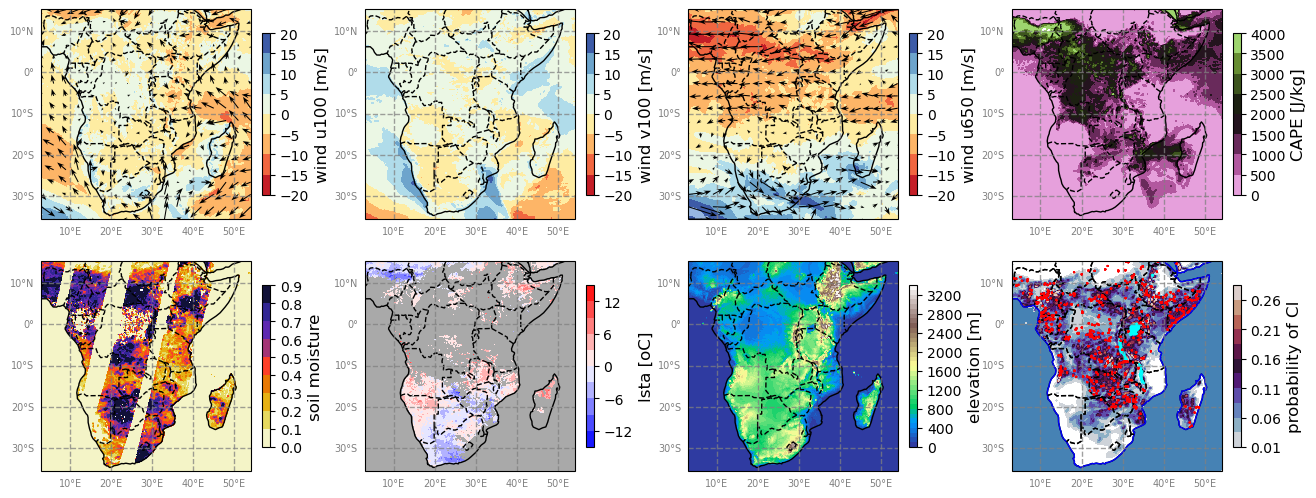

In [16]:
if runtype=='sm_lsta':
    
    fig, ax = plt.subplots(nrows=2, ncols=4,figsize=(16, 6), subplot_kw={'projection': 
                                                                         ccrs.PlateCarree()})
    
    
    plot_maps(ax[0,0], reg_lon, reg_lat, 40*inputs[0,4,:,:],
              levels_custom= np.arange(-20,21,5),plot_map='RdYlBu',plot_label='wind u100 [m/s]')
    step = 60
    factor = 1
    scale_a= 150
    q = ax[0,0].quiver(reg_lon[::step],reg_lat[::step],factor*40*inputs[0, 4, ::step, ::step],
              factor*40*inputs[0, 5, ::step, ::step],
              color='k',scale=scale_a,width=0.005,
              headwidth=5,headlength=7,headaxislength=5)
    
    plot_maps(ax[0,1], reg_lon, reg_lat, 40*inputs[0,5,:,:],
               levels_custom=  np.arange(-20,21,5),plot_map='RdYlBu',plot_label='wind v100 [m/s]')
    
    plot_maps(ax[0,2], reg_lon, reg_lat, 50*inputs[0,6,:,:],
              levels_custom=  np.arange(-20,21,5),plot_map='RdYlBu',plot_label='wind u650 [m/s]')
    q = ax[0,2].quiver(reg_lon[::step],reg_lat[::step],factor*50*inputs[0, 6, ::step, ::step],
              factor*50*inputs[0, 7, ::step, ::step],
              color='k',scale=scale_a,width=0.005,
              headwidth=5,headlength=7,headaxislength=5)
    
    #plot_maps(ax[0,3], reg_lon, reg_lat, 50*inputs[0,5,:,:],
    #          levels_custom=  np.arange(-20,21,5),plot_map='RdYlBu',plot_label='wind v650 [m/s]')
    plot_maps(ax[0,3], reg_lon, reg_lat, 12000*inputs[0,8,:,:],
              levels_custom= np.arange(0,4100,500),plot_map='vanimo',plot_label='CAPE [J/kg]')
    
    plot_maps(ax[1,0], reg_lon, reg_lat, inputs[0,0,:,:],
              levels_custom= np.arange(0,1,0.1),plot_map='CMRmap_r',plot_label='soil moisture')
    
    lsta = 20*inputs[0,2,:,:].squeeze()
    lsta[np.where(inputs[0,3,:,:]<0.5)]=np.nan
    plot_maps_lsta(ax[1,1], reg_lon, reg_lat, lsta,
              levels_custom= np.arange(-15,16,3),plot_map='bwr',plot_label='lsta [oC]')
    
    plot_maps(ax[1,2], reg_lon, reg_lat, 5000*inputs[0,9,:,:],
              levels_custom= np.arange(0,3500,100),plot_map='terrain',plot_label='elevation [m]')
    
    plot_maps(ax[1,3], reg_lon, reg_lat, predicted_ci.cpu(),
              levels_custom=  np.arange(0.01,0.31,0.025),plot_map='twilight',plot_label='probability of CI')
    ax[1,3].contour(reg_lon, reg_lat, regridded_ci,
                     transform=ccrs.PlateCarree(), linewidths=1, levels=None,colors='r')  # this is the actual plot
    ax[1,3].coastlines(color='blue')   ## adds coastlines
    ax[1,3].add_feature(cf.BORDERS, linestyle='--')#,color='black') # adds country borders
    ax[1,3].add_feature(cf.OCEAN,color='steelblue')
    ax[1,3].add_feature(cf.LAKES,color='cyan') # adds country borders
    
    
    #ax.set_xlim(xmin,xmax)
    #ax.set_ylim(ymin,ymax)
    
    #ax.set_ylim(start_lat,end_lat)
    #plt.savefig('sample_CI_figs/model_architecture_test/pred_CI_ex_'+str(pred_time)+'_LST_2xfeatures_3xConv.png', dpi=400)


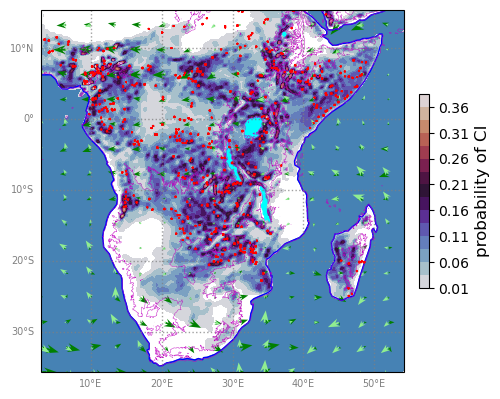

In [17]:
if runtype=='sm_lsta':
    
    fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(5, 5), subplot_kw={'projection': ccrs.PlateCarree()})
    
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=1, color='gray', alpha=0.75, linestyle=':')
    gl.top_labels = False
    gl.right_labels = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 7, 'color': 'gray'}
    gl.ylabel_style = {'size': 7, 'color': 'gray'}
    
    m=ax.contourf(reg_lon, reg_lat, predicted_ci.cpu(),
                  transform=ccrs.PlateCarree(), levels=np.arange(0.01,0.41,0.025),cmap='twilight')  # this is the actual plot
    cbar = plt.colorbar(m, fraction=0.025, pad=0.04)
    cbar.set_label('probability of CI',fontsize=12)
    
    ax.contour(reg_lon, reg_lat, 5000*inputs[0,9,:,:],
                    transform=ccrs.PlateCarree(), linewidths=0.3,levels=np.arange(0,5000,1000),colors='m')  # elevation
    
    #ax.contour(reg_lon, reg_lat, inputs[0,1,:,:],
     #               transform=ccrs.PlateCarree(), linewidths=0.1,levels=[0,0.5,1],colors='orange')  # this is the actual plot
    
    step = 70
    factor = 1
    scale_a= 400
    ax.quiver(reg_lon[::step],reg_lat[::step],factor*50*inputs[0, 6, ::step, ::step],
              factor*50*inputs[0, 7, ::step, ::step],
              color='g',scale=scale_a,width=0.005,
              headwidth=5,headlength=7,headaxislength=5)
    ax.quiver(reg_lon[::step],reg_lat[::step],factor*40*inputs[0, 4, ::step, ::step],
              factor*40*inputs[0, 5, ::step, ::step],
              color='lightgreen',scale=scale_a,width=0.005,
              headwidth=5,headlength=7,headaxislength=5)
    
    ax.contour(reg_lon, reg_lat, regridded_ci,
                    transform=ccrs.PlateCarree(), linewidths=0.5, levels=None,colors='r')  # this is the actual plot
    #ax.contour(reg_lon, reg_lat, regridded_lightning,
     #               transform=ccrs.PlateCarree(), linewidths=0.5, levels=None,colors='r')  # this is the actual plot
    ax.coastlines(color='blue')   ## adds coastlines
    #ax.add_feature(cf.BORDERS, linestyle='--')#,color='black') # adds country borders
    ax.add_feature(cf.OCEAN,color='steelblue')
    ax.add_feature(cf.LAKES,color='cyan') # adds country borders
    
    #ax.set_xlim(-20,30)
    #ax.set_ylim(-20,15)
    
    #ax.set_ylim(start_lat,end_lat)
    #plt.savefig('sample_CI_figs/model_architecture_test/pred_CI_ex_'+str(pred_time)+'_1024_0p05_LST_2Feat_3Conv.png', dpi=400)
    
    #plt.show()


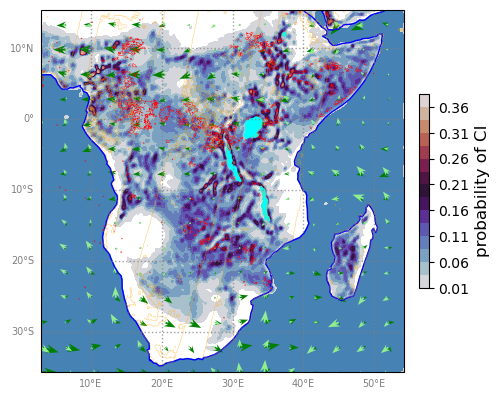

In [29]:
if runtype=='sm':
    
    fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(5, 5), subplot_kw={'projection': ccrs.PlateCarree()})
    
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=1, color='gray', alpha=0.75, linestyle=':')
    gl.top_labels = False
    gl.right_labels = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 7, 'color': 'gray'}
    gl.ylabel_style = {'size': 7, 'color': 'gray'}
    
    m=ax.contourf(reg_lon, reg_lat, predicted_ci.cpu(),
                  transform=ccrs.PlateCarree(), levels=np.arange(0.01,0.41,0.025),cmap='twilight')  # this is the actual plot
    cbar = plt.colorbar(m, fraction=0.025, pad=0.04)
    cbar.set_label('probability of CI',fontsize=12)
    
    ax.contour(reg_lon, reg_lat, regridded_lightning,
                    transform=ccrs.PlateCarree(), linewidths=0.3, levels=None,colors='r')  # this is the actual plot
   
    ax.contour(reg_lon, reg_lat, inputs[0,1,:,:],
                    transform=ccrs.PlateCarree(), linewidths=0.1,levels=[0,0.5,1],colors='orange')  # this is the actual plot
    
    step = 70
    factor = 1
    scale_a= 400
    ax.quiver(reg_lon[::step],reg_lat[::step],factor*50*inputs[0, 4, ::step, ::step],
              factor*50*inputs[0, 5, ::step, ::step],
              color='g',scale=scale_a,width=0.005,
              headwidth=5,headlength=7,headaxislength=5)
    ax.quiver(reg_lon[::step],reg_lat[::step],factor*40*inputs[0, 2, ::step, ::step],
              factor*40*inputs[0, 3, ::step, ::step],
              color='lightgreen',scale=scale_a,width=0.005,
              headwidth=5,headlength=7,headaxislength=5)
    
    
    #ax.contour(reg_lon, reg_lat, true_ci.squeeze(),
    #                transform=ccrs.PlateCarree(), linewidths=1, levels=None,colors='r')  # this is the actual plot
    ax.coastlines(color='blue')   ## adds coastlines
    #ax.add_feature(cf.BORDERS, linestyle='--')#,color='black') # adds country borders
    ax.add_feature(cf.OCEAN,color='steelblue')
    ax.add_feature(cf.LAKES,color='cyan') # adds country borders
    
    #ax.set_xlim(-20,30)
    #ax.set_ylim(-20,15)
    
    #ax.set_ylim(start_lat,end_lat)
    #plt.savefig('sample_CI_figs/model_architecture_test/pred_CI_ex_'+str(pred_time)+'_1024_0p05_LST_2Feat_3Conv.png', dpi=400)
    
    #plt.show()


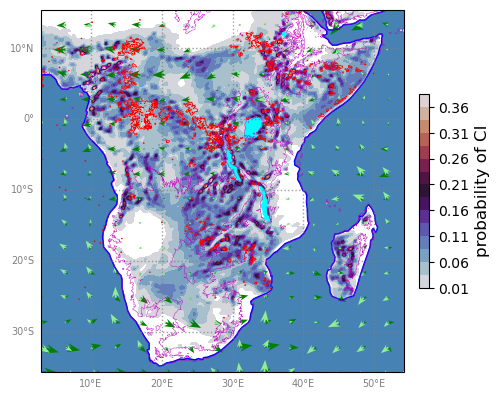

In [41]:
if runtype=='nl':
    fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(5, 5), subplot_kw={'projection': ccrs.PlateCarree()})
    
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=1, color='gray', alpha=0.75, linestyle=':')
    gl.top_labels = False
    gl.right_labels = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 7, 'color': 'gray'}
    gl.ylabel_style = {'size': 7, 'color': 'gray'}
    
    m=ax.contourf(reg_lon, reg_lat, predicted_ci.cpu(),
                  transform=ccrs.PlateCarree(), levels=np.arange(0.01,0.41,0.025),cmap='twilight')  # this is the actual plot
    cbar = plt.colorbar(m, fraction=0.025, pad=0.04)
    cbar.set_label('probability of CI',fontsize=12)
    
    ax.contour(reg_lon, reg_lat, 5000*inputs[0,5,:,:],
               transform=ccrs.PlateCarree(), linewidths=0.3,levels=np.arange(0,4000,1000),colors='m')  # elevation
    
    # ax.contour(reg_lon, reg_lat, inputs[0,1,:,:],
    #                 transform=ccrs.PlateCarree(), linewidths=0.1,levels=[0,0.5,1],colors='orange')  # this is the actual plot
    step = 70
    factor = 1
    scale_a= 400
    ax.quiver(reg_lon[::step],reg_lat[::step],factor*50*inputs[0, 2, ::step, ::step],
              factor*50*inputs[0, 3, ::step, ::step],
              color='g',scale=scale_a,width=0.005,
              headwidth=5,headlength=7,headaxislength=5)
    ax.quiver(reg_lon[::step],reg_lat[::step],factor*40*inputs[0, 0, ::step, ::step],
              factor*40*inputs[0, 1, ::step, ::step],
              color='lightgreen',scale=scale_a,width=0.005,
              headwidth=5,headlength=7,headaxislength=5)
      
    
    ax.contour(reg_lon, reg_lat, regridded_lightning,
                    transform=ccrs.PlateCarree(), linewidths=0.5, levels=None,colors='r')  # this is the actual plot
    ax.coastlines(color='blue')   ## adds coastlines
    #ax.add_feature(cf.BORDERS, linestyle='--')#,color='black') # adds country borders
    ax.add_feature(cf.OCEAN,color='steelblue')
    ax.add_feature(cf.LAKES,color='cyan') # adds country borders
    
    #ax.set_xlim(-20,30)
    #ax.set_ylim(-20,15)
    
    #ax.set_ylim(start_lat,end_lat)
    #plt.savefig('sample_CI_figs/model_architecture_test/pred_CI_ex_'+str(pred_time)+'_1024_0p05_LST_2Feat_3Conv.png', dpi=400)
    
    #plt.show()


In [50]:
# # predicted_ci.cpu(), regridded_lightning
# #with open('nl_pred_ci.pkl','wb') as file:
# #     pickle.dump([np.array(predicted_ci.cpu()), regridded_lightning],file)
# # predicted_ci.cpu(), regridded_lightning
# with open('nl_pred_ci.pkl','rb') as file:
#      nl_pred_ci, _ = pickle.load(file)

# #with open('sm_lsta_pred_ci.pkl','rb') as file:
# #    pickle.dump([np.array(predicted_ci.cpu())],file)
# sm_lsta_pred_ci = np.array(predicted_ci.cpu())
# diff_pred_ci = sm_lsta_pred_ci-nl_pred_ci
# ind_mask= np.where((5000*inputs[0,9,:,:].squeeze())<=1)
# diff_pred_ci[ind_mask]=np.nan

/tmp/ipykernel_1245046/2923952342.py:10: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  sm_lsta_pred_ci = np.array(predicted_ci.cpu())


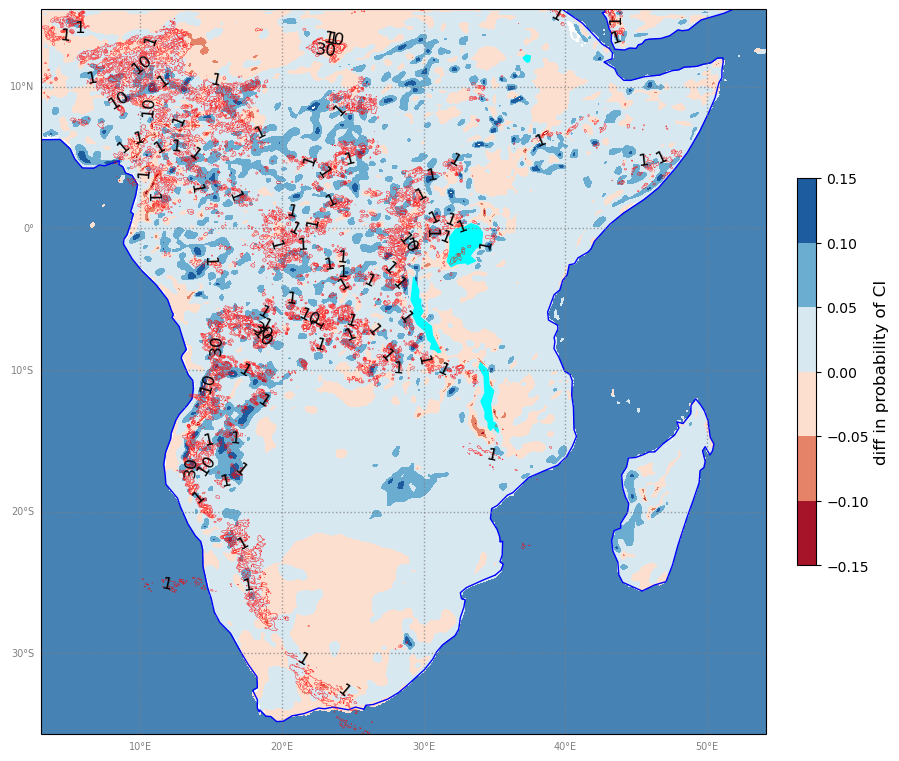

In [62]:
# fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(10, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=1, color='gray', alpha=0.75, linestyle=':')
# gl.top_labels = False
# gl.right_labels = False
# gl.xformatter = LONGITUDE_FORMATTER
# gl.yformatter = LATITUDE_FORMATTER
# gl.xlabel_style = {'size': 7, 'color': 'gray'}
# gl.ylabel_style = {'size': 7, 'color': 'gray'}

# m=ax.contourf(reg_lon, reg_lat, diff_pred_ci,
#               transform=ccrs.PlateCarree(), levels=np.arange(-0.15,0.151,0.05),cmap='RdBu')  # this is the actual plot
# cbar = plt.colorbar(m, fraction=0.025, pad=0.04)
# cbar.set_label('diff in probability of CI',fontsize=12)
 

# cs = ax.contour(
#     reg_lon, reg_lat, regridded_lightning,
#     transform=ccrs.PlateCarree(),
#     linewidths=0.3,
#     levels=[1,10,30,50],
#     colors='r'
# )

# ax.clabel(
#     cs,
#     inline=True,      # labels drawn on the contour lines
#     fontsize=12,
#     colors='black',
#     fmt='%1.0f'       # adjust format as needed
# )

# ax.coastlines(color='blue')   ## adds coastlines
# #ax.add_feature(cf.BORDERS, linestyle='--')#,color='black') # adds country borders
# ax.add_feature(cf.OCEAN,color='steelblue')
# ax.add_feature(cf.LAKES,color='cyan') # adds country borders

# #ax.set_xlim(-20,30)
# #ax.set_ylim(-20,0)

# #ax.set_ylim(start_lat,end_lat)
# #plt.savefig('sample_CI_figs/model_architecture_test/pred_CI_ex_'+str(pred_time)+'_1024_0p05_LST_2Feat_3Conv.png', dpi=400)

# #plt.show()
